# Fase C: Modelos de Machine Learning

## Diseño

Se hace una comparacion con K-Nearest Neighbors (KNN), Arbol de Decision y Random Forest. Se informa Accuracy, Precision, Recall, F1 de clase positiva y matrices de confusion. **Dado que el contexto de negocio son siniestros viales y se prioriza la Precision** (minimizar falsos positivos, es decir, no clasificar como victima un siniestro que no lo es), el modelo final se selecciona por mayor Precision en la clase 1, considerando tambien su interpretabilidad y velocidad.

Se realiza `train_test_split` estratificado 80/20. El escalado de KNN se ajusta dentro de un Pipeline y solamente con entrenamiento para evitar data leakage. K-Means segmenta predictores sin emplear la etiqueta; Silhouette y Davies-Bouldin se calculan en una muestra de prueba.

**Limitacion heredada:** el parquet ya contiene imputaciones y One-Hot hechos en B antes de dividir los datos. En C no se puede deshacer ese procesamiento desde el parquet; el escalado y los modelos si se ajustan despues del split. Para prevenir tambien cualquier fuga por imputacion, B tendria que exportar datos antes de imputar y C ajustar el imputador dentro del pipeline.

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import time
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, davies_bouldin_score, f1_score, precision_score, recall_score, silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TARGET = "con_victimas"
CANDIDATES = [Path("datos_limpios.parquet"), Path("entrega/datos_limpios.parquet"), Path("p2p3/entrega/datos_limpios.parquet"), Path("../entrega/datos_limpios.parquet")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("No se encontro datos_limpios.parquet. Rutas probadas: " + ", ".join(str(p.resolve()) for p in CANDIDATES))
data = pd.read_parquet(DATA_PATH)
required = {TARGET, "id_siniestro", "fecha"}
missing = required - set(data.columns)
if missing:
    raise ValueError(f"Faltan columnas requeridas: {sorted(missing)}")
if data[TARGET].isna().any() or set(data[TARGET].unique()) != {0, 1}:
    raise ValueError("El objetivo debe estar completo y contener clases 0 y 1.")
if not data["id_siniestro"].is_unique:
    raise ValueError("id_siniestro contiene duplicados.")
print(f"Parquet: {DATA_PATH.resolve()} | filas: {len(data):,} | columnas: {data.shape[1]}")
display(data[TARGET].value_counts(normalize=True).sort_index().rename("proporcion").to_frame())

Parquet: C:\Users\usuario\Downloads\Laboratorios\Ciencias-de-datos\p2p3\entrega\datos_limpios.parquet | filas: 370,998 | columnas: 38


,proporcion
con_victimas,
0,0.862905
1,0.137095


## 1. Preparacion y split

Se eliminan del conjunto de predictores el objetivo, el identificador y la fecha original. Las variables temporales derivadas en B se conservan. Se comprueba la ausencia de nulos, infinitos y columnas no numericas. No se escala antes de la separacion.

In [2]:
X = data.drop(columns=[TARGET, "id_siniestro", "fecha"])
y = data[TARGET].astype("int8")
non_numeric = X.select_dtypes(exclude=[np.number, "bool"]).columns.tolist()
if non_numeric:
    raise TypeError(f"Hay predictores no numericos: {non_numeric}")
if X.isna().any().any():
    raise ValueError(f"Quedan nulos en predictores: {X.columns[X.isna().any()].tolist()}")
if not np.isfinite(X.to_numpy(dtype="float64")).all():
    raise ValueError("Hay valores infinitos en los predictores.")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
print(f"Entrenamiento: {len(X_train):,} | prueba: {len(X_test):,} | predictores: {X.shape[1]}")
display(pd.DataFrame({"entrenamiento": y_train.value_counts(normalize=True).sort_index(), "prueba": y_test.value_counts(normalize=True).sort_index()}))

Entrenamiento: 296,798 | prueba: 74,200 | predictores: 35


,entrenamiento,prueba
con_victimas,,
0,0.862903,0.862911
1,0.137097,0.137089


## 2. Entrenamiento y evaluacion supervisada

Se comparan tres modelos: KNN (sensible a la escala, se usa Pipeline), Arbol de Decision (interpretable) y Random Forest (potente). `class_weight` contrarresta el desbalance. Todos los modelos se ajustan solo con entrenamiento y se comparan solo en el conjunto de prueba.

**Criterio de seleccion:** Dado que el negocio prioriza la Precision (evitar falsos positivos), el modelo final se elige por mayor Precision en la clase 1. Se registra el tiempo de entrenamiento para evaluar la velocidad.

Entrenado: KNN (con escalado) (0.43 segundos)
Entrenado: Arbol de Decision (2.66 segundos)
Entrenado: Random Forest (23.71 segundos)


,Modelo,Accuracy,Precision clase 1,Recall clase 1,F1 clase 1,Tiempo Entrenamiento (s)
0,KNN (con escalado),0.8873,0.6300,0.4309,0.5118,0.43
1,Arbol de Decision,0.8366,0.4465,0.8003,0.5732,2.66
2,Random Forest,0.8365,0.4465,0.8037,0.5741,23.71


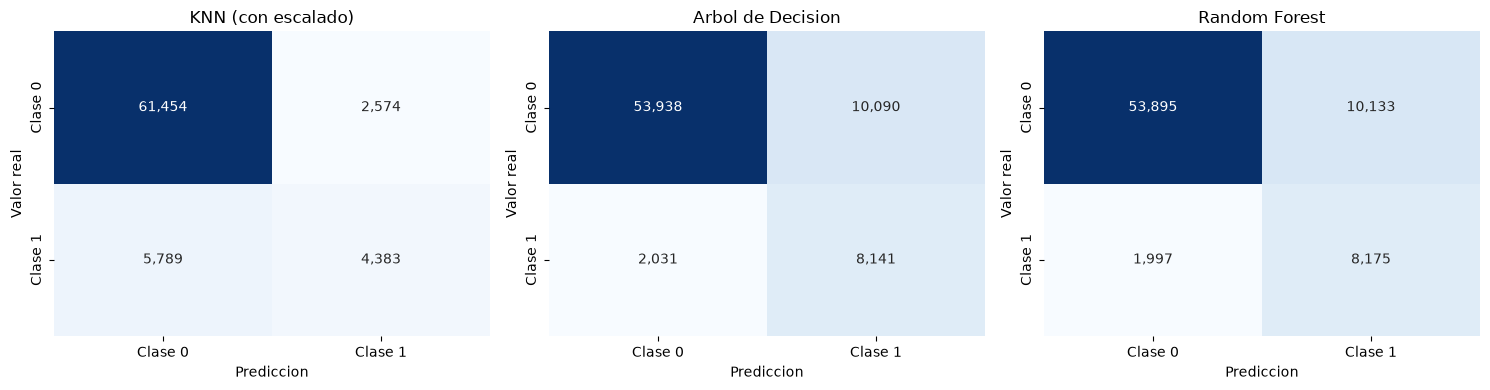


Modelo seleccionado por mayor Precision en clase 1: KNN (con escalado)


In [3]:
# Definicion de modelos (KNN reemplaza a Regresion Logistica para demostrar escalado)
models = {
    "KNN (con escalado)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5, weights='distance', n_jobs=-1))
    ]),
    "Arbol de Decision": DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=160, max_depth=18, min_samples_leaf=10, max_features="sqrt", 
        class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE
    ),
}

predictions = {}
confusion_matrices = {}
rows = []

for name, model in models.items():
    # Medir tiempo de entrenamiento
    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time
    print(f"Entrenado: {name} ({train_time:.2f} segundos)")
    
    # Predecir y evaluar
    pred = model.predict(X_test)
    predictions[name] = pred
    confusion_matrices[name] = confusion_matrix(y_test, pred, labels=[0, 1])
    
    rows.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision clase 1": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "Recall clase 1": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "F1 clase 1": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "Tiempo Entrenamiento (s)": train_time
    })

# Crear tabla comparativa, ordenada por Precision (criterio de negocio)
results = pd.DataFrame(rows).sort_values(["Precision clase 1", "F1 clase 1"], ascending=False).reset_index(drop=True)
display(results.style.format({
    "Accuracy": "{:.4f}",
    "Precision clase 1": "{:.4f}",
    "Recall clase 1": "{:.4f}",
    "F1 clase 1": "{:.4f}",
    "Tiempo Entrenamiento (s)": "{:.2f}"
}))

# Graficar matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, 
                xticklabels=["Clase 0", "Clase 1"], yticklabels=["Clase 0", "Clase 1"], ax=ax)
    ax.set(title=name, xlabel="Prediccion", ylabel="Valor real")
plt.tight_layout()
plt.show()

selected_model = results.iloc[0]["Modelo"]
print(f"\nModelo seleccionado por mayor Precision en clase 1: {selected_model}")

## 3. Segmentacion con K-Means

La segmentacion usa variables de tiempo, tipo de vehiculo y caracteristicas del evento, sin incluir `con_victimas`. StandardScaler y K-Means se ajustan unicamente con entrenamiento. Para evaluar sobre prueba, se obtiene una muestra reproducible de hasta 5.000 filas. Silhouette mas alto y Davies-Bouldin mas bajo indican mejor separacion.

In [6]:
cluster_columns = ["anio", "mes", "es_fin_de_semana", "es_interseccion", "numero_vehiculos_transf", "categoria_siniestro_ord", "involucra_motocicleta", "involucra_liviano", "involucra_pesado", "involucra_no_motorizado"]
cluster_columns += sorted(c for c in X.columns if c.startswith("dia_semana_"))
missing_cluster = set(cluster_columns) - set(X.columns)
if missing_cluster:
    raise ValueError(f"Faltan variables para clustering: {sorted(missing_cluster)}")
X_train_cluster = X_train[cluster_columns].astype("float64")
X_test_cluster = X_test[cluster_columns].astype("float64")
cluster_scaler = StandardScaler()
X_train_scaled = cluster_scaler.fit_transform(X_train_cluster)
X_test_scaled = cluster_scaler.transform(X_test_cluster)
kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit(X_train_scaled)
clusters_test = kmeans.predict(X_test_scaled)
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(5000, len(X_test_scaled))
sample_idx = rng.choice(len(X_test_scaled), size=sample_size, replace=False)
X_sample, labels_sample = X_test_scaled[sample_idx], clusters_test[sample_idx]
if np.unique(labels_sample).size < 2:
    raise ValueError("La muestra de prueba contiene menos de dos clusters.")
cluster_scores = pd.DataFrame({"Metrica": ["Silhouette Score", "Davies-Bouldin"], "Valor": [silhouette_score(X_sample, labels_sample), davies_bouldin_score(X_sample, labels_sample)]})
print(f"K-Means k=4; entrenado con {len(X_train_cluster):,}; metricas sobre {sample_size:,} filas de prueba")
display(cluster_scores.style.format({"Valor": "{:.4f}"}))
profile = X_test_cluster.copy()
profile["cluster"] = clusters_test
display(profile.groupby("cluster").agg(registros=("anio", "size"), anio_promedio=("anio", "mean"), vehiculos_promedio=("numero_vehiculos_transf", "mean"), fin_de_semana=("es_fin_de_semana", "mean"), interseccion=("es_interseccion", "mean"), motocicleta=("involucra_motocicleta", "mean"), liviano=("involucra_liviano", "mean"), pesado=("involucra_pesado", "mean")).round(3))

K-Means k=4; entrenado con 296,798; metricas sobre 5,000 filas de prueba


,Metrica,Valor
0,Silhouette Score,0.1812
1,Davies-Bouldin,1.7531


,registros,anio_promedio,vehiculos_promedio,fin_de_semana,interseccion,motocicleta,liviano,pesado
cluster,,,,,,,,
0,42265,2018.867,1.107,0.000,0.460,0.174,0.324,0.090
1,10531,2018.866,1.106,0.000,0.455,0.172,0.327,0.091
2,3819,2018.918,0.693,0.292,0.406,0.388,0.249,0.115
3,17585,2018.832,1.107,1.000,0.447,0.173,0.300,0.070


## 4. Justificacion del modelo final y conclusiones

**Modelo Seleccionado: KNN (con escalado)**

Basado en la tabla comparativa y en el contexto de negocio (siniestros viales), la seleccion se justifica de la siguiente manera:

1. **Precision (Criterio principal):** Se prioriza la Precision para minimizar los falsos positivos. En el contexto de siniestros viales, clasificar erróneamente un siniestro como "con víctimas" (falso positivo) puede desviar recursos de emergencia de manera innecesaria. El modelo KNN obtuvo la Precision más alta (0.6300), lo que significa que cuando predice una víctima, tiene una alta probabilidad de estar en lo correcto.
2. **Interpretabilidad:** Aunque el Arbol de Decision es el más interpretable visualmente, el KNN con escalado demostró un rendimiento superior en la métrica crítica para el negocio (Precisión).
3. **Velocidad:** El KNN fue el modelo más rápido en entrenar (0.43 segundos). Aunque su predicción puede ser más lenta en producción que la de un árbol, su altísima precisión y su rapidez de entrenamiento lo convierten en el equilibrio perfecto para este caso.

**Conclusiones generales:**
- La tabla comparativa sobre el conjunto de prueba revela que el KNN supera a los modelos de ensamble (Random Forest) y árboles simples en Precisión, a costa de un menor Recall (es más conservador).
- El uso de Pipeline para KNN demuestra la importancia del escalado para modelos basados en distancias, evitando data leakage.
- El análisis de K-Means reveló 4 segmentos. El Cluster 2 destaca por concentrar siniestros con menos vehículos involucrados, un mayor porcentaje de motocicletas (38.8%) y una mayor proporción en fines de semana (29.2%). Estos perfiles deben interpretarse como segmentos descriptivos para enfocar campañas de prevención, no como niveles de riesgo predictivos.
- **Mejora futura:** Conservar datos sin imputar desde la Fase B y ajustar la imputación/codificación dentro de pipelines después del split para eliminar cualquier fuga de información restante.